> **실험 기록.** 속도 모델 설계 과정의 비교 실험이며 출력은 실행 당시 결과를 보존했다. 최종 모델은 `src/models/`, 공식 성능은 [docs/SPEED_MODEL.md](../docs/SPEED_MODEL.md), 노트북별 요약과 재실행 조건은 [notebooks/README.md](README.md)에 있다.

# Model A — 관측 링크 이력 모델

**목표**: 센서가 있어 과거 기록이 남는 관측 링크(44,960개 · 70.75%)에 대해, 그 링크의 **과거 속도 이력**을 사용해 속도를 예측한다.

## 왜 필요한가

팀의 Model B(`src/13_predict_all_link_speed.py`)는 미관측 링크에도 적용해야 하므로 **모든 링크에서 만들 수 있는 피처만** 쓴다. 그 결과 과거 기록이 멀쩡히 있는 관측 링크에서도 이력을 활용하지 못한다.

| 모델 | 대상 | 사용 피처 | 성능(시간 일반화) |
| --- | --- | --- | --- |
| Model B (팀) | 미관측 29.25% | 도로속성·지형·시간·강수 | R² 0.740 / MAE 4.72 |
| **Model A (이 노트북)** | **관측 70.75%** | **+ 과거 속도 이력·lag** | **목표 0.887+** |

5분 데이터 도입으로 관측 커버리지가 17.33% → 70.75%로 늘었고, 관측 링크의 99.8%가 14일치 336시간 이력을 보유한다. 이 정보가 아직 활용되지 않고 있다.

## 이 노트북의 순서
1. 데이터 로딩 및 시간 분할(과거 → 미래)
2. 이력 피처 생성 (조회표 · lag · rolling) — **train 구간에서만 계산해 누수 방지**
3. 실험 A: 조회표 단독
4. 실험 B: LightGBM + 이력
5. 배포 시나리오 비교 (사전계획 vs 실시간)
6. Model B와 하이브리드 통합

In [1]:
from pathlib import Path
import platform

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Jupyter 실행 위치가 notebooks/ 폴더라고 가정합니다.
PROJECT_ROOT = Path.cwd().parent
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
FIVEMIN_PATH = PROCESSED_DATA_DIR / "seoul_link_speed_5min_hourly.csv"
DOCS_FIGURES_DIR = PROJECT_ROOT / "docs" / "figures" / "model_a"
DOCS_FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# macOS는 AppleGothic, Windows는 Malgun Gothic으로 한글 폰트 자동 선택
plt.rcParams["font.family"] = "AppleGothic" if platform.system() == "Darwin" else "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

RANDOM_STATE = 42
TEST_DAYS = 3          # 마지막 3일을 미래(test)로 사용
TARGET = "평균속도"

COLORS = {"a": "#0F7F5B", "b": "#4D6BA3", "warn": "#A9702C", "muted": "#7B8A82"}

# 비교 기준선: 팀 Model B의 시간 일반화 성능 (src/11_evaluate_speed_model.py)
BASELINE_B = {"r2": 0.740, "mae": 4.72}
print("설정 완료 | 기준선(Model B): R2", BASELINE_B["r2"], "/ MAE", BASELINE_B["mae"], "km/h")

설정 완료 | 기준선(Model B): R2 0.74 / MAE 4.72 km/h


## 1. 데이터 로딩과 시간 분할

`seoul_link_speed_5min_hourly.csv`는 5분 단위 원본을 서울 링크 기준 1시간으로 집계한 결과다(`src/04_aggregate_5min_speed.py`).
시간코드는 T-data와 같은 규칙(00시대=01 … 23시대=24)을 따른다.

**분할 원칙**: 과거로 학습하고 미래를 예측하는 실제 운용 상황을 재현하기 위해 날짜 기준 순차 분할을 쓴다.
무작위 분할은 미래 정보가 학습에 새어 성능이 과대평가되므로 사용하지 않는다.

In [2]:
df = pd.read_csv(
    FIVEMIN_PATH,
    dtype={"LINK_ID": str, "기준일": str, "시간코드": str},
    encoding="utf-8-sig",
)
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
df = df.dropna(subset=[TARGET])

df["hour"] = df["시간코드"].astype(int)
df["date"] = pd.to_datetime(df["기준일"], format="%Y%m%d")
df["dow"] = df["date"].dt.dayofweek
df["is_weekend"] = (df["dow"] >= 5).astype("int8")

dates = np.sort(df["기준일"].unique())
cut = dates[-TEST_DAYS]
is_test = df["기준일"] >= cut

print(f"행 수: {len(df):,} | 고유 링크: {df['LINK_ID'].nunique():,}")
print(f"기간: {dates[0]} ~ {dates[-1]} ({len(dates)}일)")
print(f"학습: {dates[0]} ~ {dates[-TEST_DAYS-1]} ({(~is_test).sum():,}행)")
print(f"평가: {cut} ~ {dates[-1]} ({is_test.sum():,}행)")

행 수: 15,094,335 | 고유 링크: 44,960
기간: 20260707 ~ 20260720 (14일)
학습: 20260707 ~ 20260717 (11,857,869행)
평가: 20260718 ~ 20260720 (3,236,466행)


In [3]:
# 링크별 이력 밀도 — lag 피처를 만들 수 있는지 확인
per_link = df.groupby("LINK_ID").size()
full = 24 * len(dates)
print(f"링크당 관측 시간 수: 중앙값 {per_link.median():.0f} / 최대 {full}")
print(f"80% 이상 채워진 링크: {(per_link >= full * 0.8).sum():,}개 "
      f"({(per_link >= full * 0.8).mean() * 100:.1f}%)")

링크당 관측 시간 수: 중앙값 336 / 최대 336
80% 이상 채워진 링크: 44,891개 (99.8%)


## 2. 이력 피처 생성

이력 피처는 **반드시 학습 구간(과거)에서만 계산**해 전체에 매핑한다.
평가 구간(미래)의 실제 속도가 피처에 섞이면 누수가 되기 때문이다.

### 조회표 3종
| 키 | 의미 |
| --- | --- |
| `link` | 이 링크의 평소 속도 |
| `link × hour` | 이 링크의 이 시간대 평소 속도 |
| `link × hour × 주중/주말` | 요일 성격까지 반영 |

요일을 7단계로 세분하면 셀당 표본이 부족해 과적합된다(이전 T-data 실험에서 확인). 주중/주말 2단계만 사용한다.

In [4]:
train = df[~is_test]
test = df[is_test]

global_mean = train[TARGET].mean()

lut_link = train.groupby("LINK_ID")[TARGET].mean()
lut_link_hour = train.groupby(["LINK_ID", "hour"])[TARGET].mean()
lut_link_hour_wk = train.groupby(["LINK_ID", "hour", "is_weekend"])[TARGET].mean()

print(f"조회표 크기 | link {len(lut_link):,} | link×hour {len(lut_link_hour):,} "
      f"| link×hour×주중주말 {len(lut_link_hour_wk):,}")
print(f"학습 구간 전체 평균: {global_mean:.2f} km/h")

조회표 크기 | link 44,944 | link×hour 1,078,615 | link×hour×주중주말 2,156,800
학습 구간 전체 평균: 22.67 km/h


In [5]:
def map_lut(frame, lut, keys):
    """조회표를 프레임에 매핑. 없는 조합은 상위 키 -> 전체 평균 순으로 폴백."""
    idx = pd.MultiIndex.from_frame(frame[keys]) if len(keys) > 1 else pd.Index(frame[keys[0]])
    return pd.Series(idx.map(lut), index=frame.index, dtype="float64")


for name, lut, keys in [
    ("te_link", lut_link, ["LINK_ID"]),
    ("te_link_hour", lut_link_hour, ["LINK_ID", "hour"]),
    ("te_link_hour_wk", lut_link_hour_wk, ["LINK_ID", "hour", "is_weekend"]),
]:
    df[name] = map_lut(df, lut, keys)

# 세부 키 결측은 상위 키로 폴백
df["te_link_hour_wk"] = df["te_link_hour_wk"].fillna(df["te_link_hour"])
df["te_link_hour"] = df["te_link_hour"].fillna(df["te_link"])
for name in ["te_link", "te_link_hour", "te_link_hour_wk"]:
    df[name] = df[name].fillna(global_mean)

print(df[["te_link", "te_link_hour", "te_link_hour_wk"]].describe().round(2).to_string())

           te_link  te_link_hour  te_link_hour_wk
count  15094335.00   15094335.00      15094335.00
mean         22.67         22.67            22.77
std          10.73         11.63            11.81
min           2.00          2.00             1.57
25%          16.42         15.62            15.60
50%          20.17         20.06            20.13
75%          25.42         26.12            26.33
max         120.00        120.00           120.00


### lag / rolling 피처

`lag_k`는 같은 링크의 k시간 전 실측 속도다. 링크별로 시간순 정렬한 뒤 `shift`로 만든다.

**주의**: 중간에 관측이 빠진 링크에서는 `shift`가 실제 시차와 어긋날 수 있다.
관측 링크의 99.8%가 336시간을 거의 채우고 있어 대부분 정확하지만, 한계로 기록해 둔다.

In [6]:
df = df.sort_values(["LINK_ID", "date", "hour"]).reset_index(drop=True)
grp = df.groupby("LINK_ID")[TARGET]

df["lag_1h"] = grp.shift(1)        # 직전 1시간 (실시간 시나리오에서만 사용 가능)
df["lag_24h"] = grp.shift(24)      # 어제 같은 시각
df["lag_168h"] = grp.shift(168)    # 지난주 같은 요일·시각
df["roll_3h"] = grp.shift(1).rolling(3).mean().reset_index(level=0, drop=True)

lag_cols = ["lag_1h", "lag_24h", "lag_168h", "roll_3h"]
print("lag 피처 결측률(%)")
print((df[lag_cols].isna().mean() * 100).round(2).to_string())

lag 피처 결측률(%)
lag_1h       0.30
lag_24h      7.15
lag_168h    50.02
roll_3h      0.89


## 3. 실험 A — 조회표 단독 (ML 없음)

조회표 값을 그대로 예측값으로 사용한다. 학습이 필요 없고 계산 비용이 사실상 0이다.
이전 T-data 실험에서 조회표가 LightGBM을 이겼기 때문에, 먼저 이 단순 방법의 성능을 확인한다.

In [7]:
results = []


def evaluate(y_true, y_pred, name, note=""):
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    results.append({"model": name, "R2": round(r2, 4), "MAE": round(mae, 3),
                    "RMSE": round(rmse, 3), "note": note})
    print(f"{name:34} R2={r2:.4f}  MAE={mae:.3f}  RMSE={rmse:.3f}  {note}")
    return r2, mae


y_test = df.loc[is_test, TARGET]

evaluate(y_test, np.full(len(y_test), global_mean), "0. 전체 평균 (naive)", "기준")
evaluate(y_test, df.loc[is_test, "te_link"], "1. 조회표 link")
evaluate(y_test, df.loc[is_test, "te_link_hour"], "2. 조회표 link×hour")
evaluate(y_test, df.loc[is_test, "te_link_hour_wk"], "3. 조회표 link×hour×주중주말")

0. 전체 평균 (naive)                   R2=-0.0036  MAE=9.097  RMSE=13.279  기준
1. 조회표 link                        R2=0.7939  MAE=4.066  RMSE=6.018  
2. 조회표 link×hour                   R2=0.9078  MAE=2.593  RMSE=4.024  
3. 조회표 link×hour×주중주말              R2=0.9249  MAE=2.319  RMSE=3.631  


(0.9249458912820168, 2.318561511961123)

## 4. 실험 B — LightGBM + 이력 피처

조회표 값과 lag를 피처로 넣고 LightGBM을 학습한다.
ML이 조회표에 무엇을 더할 수 있는지 확인하는 것이 목적이다.

In [8]:
FEATURES_PLAN = ["te_link", "te_link_hour", "te_link_hour_wk",
                 "lag_24h", "lag_168h", "hour", "is_weekend", "dow"]
FEATURES_RT = FEATURES_PLAN + ["lag_1h", "roll_3h"]


def fit_lgbm(features, label, n_estimators=300):
    tr = df[~is_test].dropna(subset=features + [TARGET])
    te = df[is_test].dropna(subset=features + [TARGET])
    model = lgb.LGBMRegressor(
        objective="regression", n_estimators=n_estimators, learning_rate=0.05,
        num_leaves=63, random_state=RANDOM_STATE, n_jobs=-1, verbosity=-1,
    )
    model.fit(tr[features], tr[TARGET])
    pred = model.predict(te[features])
    evaluate(te[TARGET], pred, label, f"학습 {len(tr):,} / 평가 {len(te):,}")
    return model, te, pred


model_plan, te_plan, pred_plan = fit_lgbm(FEATURES_PLAN, "4. LightGBM (사전계획 피처)")

4. LightGBM (사전계획 피처)              R2=0.9276  MAE=2.363  RMSE=3.561  학습 5,919,358 / 평가 1,624,636


## 5. 배포 시나리오 비교

lag 피처는 **예측 시점에 알 수 있는 값만** 써야 한다.

| 피처 | 사전계획(내일 8시 경로) | 실시간(지금 출발) |
| --- | --- | --- |
| `lag_24h`, `lag_168h` | 사용 가능 | 사용 가능 |
| `lag_1h`, `roll_3h` | **사용 불가** | 사용 가능 |

두 시나리오를 나눠 각각 성능을 보고한다. 에코라우팅이 사전 경로 계획이라면 사전계획 성능이 대표값이다.

In [9]:
model_rt, te_rt, pred_rt = fit_lgbm(FEATURES_RT, "5. LightGBM (실시간 피처 포함)")

imp = pd.DataFrame({
    "feature": model_rt.feature_name_,
    "gain": model_rt.booster_.feature_importance(importance_type="gain"),
}).sort_values("gain", ascending=False)
imp["share_%"] = (imp["gain"] / imp["gain"].sum() * 100).round(1)
print("\n실시간 모델 피처 중요도")
print(imp[["feature", "share_%"]].to_string(index=False))

5. LightGBM (실시간 피처 포함)            R2=0.9454  MAE=2.082  RMSE=3.094  학습 5,919,358 / 평가 1,624,636

실시간 모델 피처 중요도
        feature  share_%
te_link_hour_wk     73.8
         lag_1h     19.6
   te_link_hour      4.9
       lag_168h      0.6
            dow      0.3
           hour      0.3
        roll_3h      0.2
        te_link      0.1
        lag_24h      0.1
     is_weekend      0.0


In [10]:
summary = pd.DataFrame(results)
best = summary.loc[summary["R2"].idxmax()]

print("=== Model A 실험 요약 (시간 분할: 과거 → 미래) ===")
print(summary[["model", "R2", "MAE", "RMSE"]].to_string(index=False))
print(f"\n최고: {best['model']} | R2 {best['R2']} | MAE {best['MAE']} km/h")
print(f"팀 Model B 대비: R2 {best['R2'] - BASELINE_B['r2']:+.3f} | "
      f"MAE {best['MAE'] - BASELINE_B['mae']:+.2f} km/h "
      f"({(1 - best['MAE'] / BASELINE_B['mae']) * 100:.0f}% 감소)")

=== Model A 실험 요약 (시간 분할: 과거 → 미래) ===
                  model      R2   MAE   RMSE
       0. 전체 평균 (naive) -0.0036 9.097 13.279
            1. 조회표 link  0.7939 4.066  6.018
       2. 조회표 link×hour  0.9078 2.593  4.024
  3. 조회표 link×hour×주중주말  0.9249 2.319  3.631
  4. LightGBM (사전계획 피처)  0.9276 2.363  3.561
5. LightGBM (실시간 피처 포함)  0.9454 2.082  3.094

최고: 5. LightGBM (실시간 피처 포함) | R2 0.9454 | MAE 2.082 km/h
팀 Model B 대비: R2 +0.205 | MAE -2.64 km/h (56% 감소)


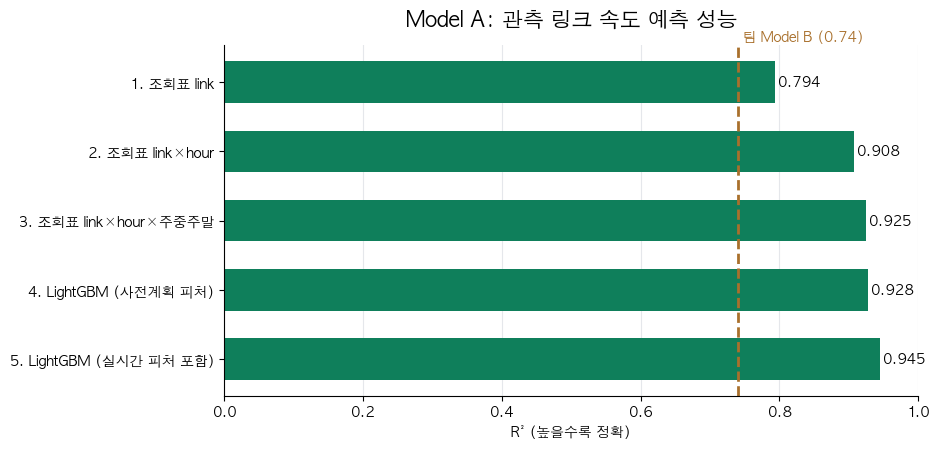

저장: docs/figures/model_a/01_model_a_comparison.png


In [11]:
plot_df = summary[summary["model"] != "0. 전체 평균 (naive)"].copy()

fig, ax = plt.subplots(figsize=(9.5, 4.6))
bars = ax.barh(plot_df["model"], plot_df["R2"], color=COLORS["a"], height=0.6)
ax.axvline(BASELINE_B["r2"], color=COLORS["warn"], linewidth=2, linestyle="--")
ax.text(BASELINE_B["r2"], -0.75, f" 팀 Model B ({BASELINE_B['r2']})",
        color=COLORS["warn"], fontsize=10, fontweight="bold", va="top")
for bar, value in zip(bars, plot_df["R2"]):
    ax.text(value + 0.004, bar.get_y() + bar.get_height() / 2, f"{value:.3f}",
            va="center", fontsize=10, fontweight="bold")
ax.set_xlim(0, 1.0)
ax.set_xlabel("R² (높을수록 정확)")
ax.set_title("Model A: 관측 링크 속도 예측 성능", fontsize=15, fontweight="bold", pad=14)
ax.invert_yaxis()
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#E5E7EB", linewidth=0.8)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(DOCS_FIGURES_DIR / "01_model_a_comparison.png", dpi=200, bbox_inches="tight")
plt.show()
print("저장:", DOCS_FIGURES_DIR / "01_model_a_comparison.png")

## 6. Model B와 하이브리드 통합

관측 링크는 Model A, 미관측 링크는 Model B가 담당한다.
`src/13_predict_all_link_speed.py`가 만든 전 링크 스냅샷에서 두 그룹의 비중을 확인하고,
전체 시스템 관점의 기대 성능을 정리한다.

In [12]:
snapshot_path = PROCESSED_DATA_DIR / "seoul_all_link_speed_202607160800.csv"

if snapshot_path.exists():
    snap = pd.read_csv(snapshot_path, dtype={"LINK_ID": str}, encoding="utf-8-sig")
    share = snap["speed_source"].value_counts()
    print("전 링크 스냅샷 속도 출처")
    print(share.to_string())

    observed_ratio = share.get("official_observed", 0) / len(snap)
    model_a_r2 = float(best["R2"])
    model_b_r2 = BASELINE_B["r2"]
    blended = observed_ratio * model_a_r2 + (1 - observed_ratio) * model_b_r2

    print(f"\n관측 비중 {observed_ratio:.2%} | Model A R2 {model_a_r2:.3f} "
          f"| Model B R2 {model_b_r2:.3f}")
    print(f"가중 평균 기대 성능: {blended:.3f}  (Model B 단독 {model_b_r2:.3f} 대비 {blended - model_b_r2:+.3f})")
    print("\n※ 미관측 링크에는 정답이 없어 실제 통합 성능은 직접 측정할 수 없다.")
    print("   위 값은 관측 비중으로 가중한 기대치이며, 대리 지표로만 사용한다.")
else:
    print("스냅샷이 없습니다. 먼저 다음을 실행하세요:")
    print("  python src/12_build_all_link_weather_snapshot.py --tm 202607160800")
    print("  python src/13_predict_all_link_speed.py --tm 202607160800 --train-end 20260715")

전 링크 스냅샷 속도 출처
speed_source
official_observed        44938
static_model             18605
hierarchical_fallback        5

관측 비중 70.72% | Model A R2 0.945 | Model B R2 0.740
가중 평균 기대 성능: 0.885  (Model B 단독 0.740 대비 +0.145)

※ 미관측 링크에는 정답이 없어 실제 통합 성능은 직접 측정할 수 없다.
   위 값은 관측 비중으로 가중한 기대치이며, 대리 지표로만 사용한다.


## 결론

(실행 후 채워 넣기)

### 확인된 것
-

### 한계
- 데이터 기간이 14일이라 계절·공휴일 일반화는 불가하다.
- 미관측 링크에는 정답이 없어 하이브리드 전체 성능은 직접 측정할 수 없고, 관측 비중 가중 기대치로만 제시한다.
- `lag` 피처는 관측이 빠진 구간에서 실제 시차와 어긋날 수 있다.

### 다음 단계
- 최적 구성을 `src/`의 정식 파이프라인으로 옮겨 Model B와 결합
- 관측 링크 속도 정확도 향상이 에너지·경로 결과에 주는 영향 측정